# SST bracket of the pretrained models

The SST bracket $[L(b), U(b)]$ (see `src/experiment.py`'s `sst_bracket`) of the externally pretrained speaker-verification models (`slurm/pretrained-{resnet34,w2vbert,wavlm}-*.submit`), over the signal one shuffled block of $b$ frames spans:

- $L(b) = EER(GS_b) - EER(GO_b)$: lower estimate, the splicing artefacts largely cancel.
- $U(b) = EER(BS_b) - EER(OS)$: upper estimate, also counts the artefacts at the joins.
- $L_{norm}$, $U_{norm}$: both divided by the headroom to chance, $50\% - EER(OS)$, so they compare across models of different baseline EER.

The test EERs come from the per-run summaries (`run{i}/final/SV_EER_test-*`) of the wandb runs. These are also logged by runs still in progress, so the bands use every completed run and average the measures over runs.

In [1]:
import sys
from dataclasses import fields
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import wandb

ROOT = Path.cwd().parent  # notebook runs from doc/
sys.path.insert(0, str(ROOT))

from src.config import TransformationConfig
from src.data.segments import BLOCK_SIZES
from src.experiment import sst_bracket

WANDB_PATH = "marbetschar-zhaw/speaker-verification"
VARIANT = "2s"  # wandb.run_postfix of the configs: "2s", "3s" or "2s-vox1o"
MODELS = {  # label: model.type
    "ResNet34 (WeSpeaker)": "WeSpeakerResNet34",
    "w2v-BERT 2.0": "W2VBertSV",
    "WavLM-ECAPA": "WavLMECAPA",
}

In [2]:
def fetch_bracket(api, model_type):
    """SST measures of the latest wandb run of model_type: {measure: (block
    span [ms], mean over runs [%-points or %])}, and the run. None if there is
    no run, or it hasn't completed a run yet."""
    runs = api.runs(WANDB_PATH, filters={"display_name": f"{model_type}-voxceleb-OS-{VARIANT}"}, order="-created_at")
    if not runs:
        return None, None
    run = runs[0]
    summary = run.summary._json_dict
    prefix = "/final/SV_EER_test-"
    run_eers = {}
    for key, value in summary.items():
        if key.startswith("run") and prefix in key:
            run_idx, strategy = key.split(prefix)
            run_eers.setdefault(run_idx, {})[strategy] = value / 100
    if not run_eers:
        return None, run
    transformation_config = {f.name: run.config["transformation"][f.name] for f in fields(TransformationConfig) if f.name in run.config["transformation"]}
    transformation = TransformationConfig(**transformation_config)
    measures = {}
    for block_size in BLOCK_SIZES:
        per_run = [sst_bracket(eers, block_size) for eers in run_eers.values()]
        for measure in per_run[0]:
            mean = np.mean([values[measure] for values in per_run]) * 100
            measures.setdefault(measure, []).append((transformation.block_span_s(block_size) * 1000, mean))
    return {measure: tuple(np.array(v) for v in zip(*points)) for measure, points in measures.items()}, (run, len(run_eers))


api = wandb.Api()
brackets = {}
for label, model_type in MODELS.items():
    bracket, info = fetch_bracket(api, model_type)
    if bracket is None:
        print(f"{label}: no completed run" + (f" ({info.name}, {info.state})" if info else ""))
        continue
    run, num_runs = info
    print(f"{label}: {run.name} ({run.id}, {run.state}), {num_runs} run(s)")
    brackets[label] = bracket

ResNet34 (WeSpeaker): WeSpeakerResNet34-voxceleb-OS-2s (8kgciyvw, running), 2 run(s)
w2v-BERT 2.0: no completed run (W2VBertSV-voxceleb-OS-2s, running)
WavLM-ECAPA: no completed run


## Band per model

$[L(b), U(b)]$ in EER %-points, one panel per model.

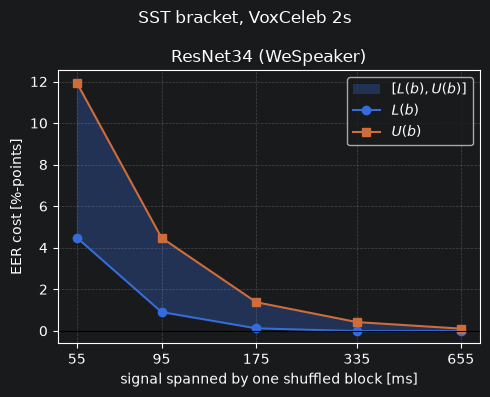

In [3]:
fig, axes = plt.subplots(1, len(brackets), figsize=(5 * len(brackets), 4), sharey=True, squeeze=False)
for ax, (label, bracket) in zip(axes[0], brackets.items()):
    span, lower = bracket["L"]
    _, upper = bracket["U"]
    ax.fill_between(span, lower, upper, alpha=0.3, label="$[L(b), U(b)]$")
    ax.plot(span, lower, "o-", label="$L(b)$")
    ax.plot(span, upper, "s-", label="$U(b)$")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_xticks(span, [f"{s:.0f}" for s in span])
    ax.minorticks_off()
    ax.set_title(label)
    ax.set_xlabel("signal spanned by one shuffled block [ms]")
    ax.grid(alpha=0.3, linestyle="--")
axes[0][0].set_ylabel("EER cost [%-points]")
axes[0][0].legend()
fig.suptitle(f"SST bracket, VoxCeleb {VARIANT}")
plt.tight_layout()

## Models compared

$[L_{norm}(b), U_{norm}(b)]$, the band relative to each model's headroom to chance, $50\% - EER(OS)$.

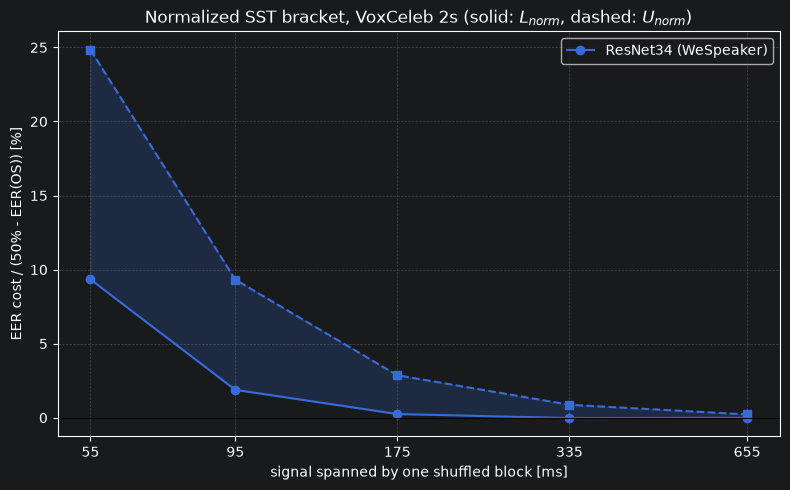

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, bracket in brackets.items():
    span, lower = bracket["L_norm"]
    _, upper = bracket["U_norm"]
    line, = ax.plot(span, lower, "o-", label=label)
    ax.plot(span, upper, "s--", color=line.get_color())
    ax.fill_between(span, lower, upper, color=line.get_color(), alpha=0.2)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
spans = sorted({s for bracket in brackets.values() for s in bracket["L_norm"][0]})
ax.set_xticks(spans, [f"{s:.0f}" for s in spans])
ax.minorticks_off()
ax.set_xlabel("signal spanned by one shuffled block [ms]")
ax.set_ylabel("EER cost / (50% - EER(OS)) [%]")
ax.set_title(f"Normalized SST bracket, VoxCeleb {VARIANT} (solid: $L_{{norm}}$, dashed: $U_{{norm}}$)")
ax.grid(alpha=0.3, linestyle="--")
ax.legend()
plt.tight_layout()